### View an experiment progress

In [1]:
# Base directory
base_dir = "/data/horse/ws/miha493e-research_project/activediffusion/data/data_40"

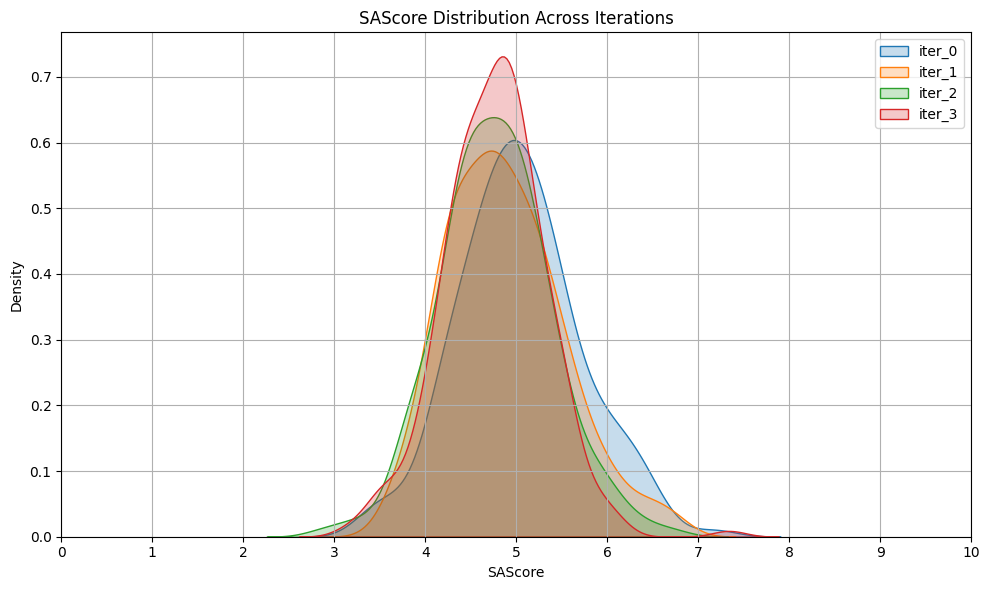

⚠ Missing files:
/data/horse/ws/miha493e-research_project/activediffusion/data/data_40/iter_4/relaxed/sascore.txt


In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import os
import re


plt.figure(figsize=(10, 6))

missing_files = []

# Loop over all iteration folders
for iter_num in sorted(
    [d for d in os.listdir(base_dir) if re.match(r"iter_\d+", d)],
    key=lambda x: int(re.search(r"\d+", x).group())
):
    sas_file = os.path.join(base_dir, iter_num, "relaxed", "sascore.txt")
    
    if os.path.exists(sas_file):
        data = pd.read_csv(sas_file, sep=r"\s+", header=None)
        sas = data[1]  # Second column
        sns.kdeplot(sas, label=f'{iter_num}', fill=True)
    else:
        missing_files.append(sas_file)
plt.xticks(range(0, 11, 1))
plt.xlabel('SAScore')
plt.ylabel('Density')
plt.title('SAScore Distribution Across Iterations')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

# Report missing files if any
if missing_files:
    print("⚠ Missing files:")
    for f in missing_files:
        print(f)


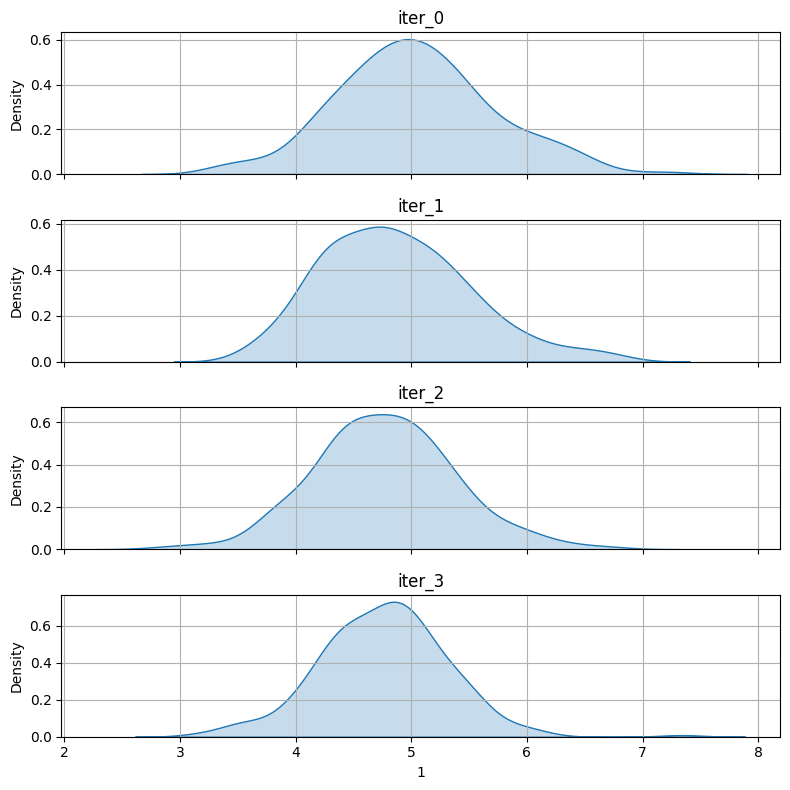

In [3]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import os, re

# Collect data
sas_data = []
iterations = []

for iter_num in sorted(
    [d for d in os.listdir(base_dir) if re.match(r"iter_\d+", d)],
    key=lambda x: int(re.search(r"\d+", x).group())
):
    sas_file = os.path.join(base_dir, iter_num, "relaxed", "sascore.txt")
    if os.path.exists(sas_file):
        data = pd.read_csv(sas_file, sep=r"\s+", header=None)
        sas_data.append(data[1])
        iterations.append(iter_num)

# Create subplots
fig, axes = plt.subplots(len(sas_data), 1, figsize=(8, 2*len(sas_data)), sharex=True)

for ax, sas, label in zip(axes, sas_data, iterations):
    sns.kdeplot(sas, fill=True, ax=ax)
    ax.set_title(label)
    ax.grid(True)

plt.tight_layout()
plt.show()


In [4]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

def load_iteration_data_from_paths(file_paths):
    all_dfs = []
    for i, path in enumerate(file_paths):
        with open(path, "r") as f:
            lines = [line.strip() for line in f if line.strip()]

        # Extract header and data line
        data_lines = [line for line in lines if not line.startswith(',mol_stable')]
        if not data_lines:
            continue

        header_line = [line for line in lines if line.startswith(',mol_stable')][0]
        header = header_line.lstrip(',').split(',')
        values = data_lines[0].lstrip(',').split(',')[1:]

        df = pd.DataFrame([values], columns=header)
        df["iteration"] = i
        df["filename"] = path
        all_dfs.append(df)

    combined_df = pd.concat(all_dfs, ignore_index=True)
    
    # Convert all columns (except filename) to numeric if possible
    for col in combined_df.columns:
        if col not in ["filename"]:
            combined_df[col] = pd.to_numeric(combined_df[col], errors='ignore')

    return combined_df


In [6]:
import pandas as pd
import matplotlib.pyplot as plt
import math

def plot_metrics_subplots(df, metrics):
    """
    Plots multiple metrics from a DataFrame on separate subplots.

    Args:
        df (pd.DataFrame): The DataFrame containing the data.
        metrics (list): A list of strings, where each string is a column name
                        representing a metric to be plotted.
    """
    if "iteration" not in df.columns:
        print("Column 'iteration' not found in data.")
        return

    existing_metrics = [metric for metric in metrics if metric in df.columns]
    non_existing_metrics = [metric for metric in metrics if metric not in df.columns]

    if non_existing_metrics:
        print(f"Metrics not found in data and will be skipped: {', '.join(non_existing_metrics)}")

    if not existing_metrics:
        print("No valid metrics found to plot.")
        return

    df_sorted = df.sort_values("iteration")
    num_metrics = len(existing_metrics)

    # Determine the grid size for the subplots
    # We'll use a square-ish layout for better visual appeal (e.g., 4 metrics -> 2x2 grid)
    num_cols = int(math.ceil(math.sqrt(num_metrics)))
    num_rows = int(math.ceil(num_metrics / num_cols))

    # Create the figure and a grid of subplots
    # sharex=True ensures that all x-axes are linked, making it easy to compare iterations
    fig, axes = plt.subplots(num_rows, num_cols, figsize=(5 * num_cols, 4 * num_rows), sharex=True)
    
    # Flatten the axes array if it's 2D for easier iteration
    axes = axes.flatten() if isinstance(axes, (list, tuple, object)) else [axes]

     # Colors from seaborn palette
    palette = sns.color_palette("tab10", len(metrics))

    # Plot each metric on its own subplot
    for i, metric in enumerate(existing_metrics):
        axes[i].plot(df_sorted["iteration"], df_sorted[metric], marker='o', color=palette[i], linewidth=2)
        axes[i].set_title(metric, fontsize=14, fontweight='bold')
        axes[i].set_xlabel('Iteration', fontsize=10)
        axes[i].set_ylabel(metric, fontsize=10)
        axes[i].grid(True, linestyle='--', alpha=0.6)
    
    # Set a common x-label for the entire figure to avoid clutter
    fig.supxlabel("Iteration", fontsize=12)
    fig.suptitle("Metrics over Iterations", fontsize=16)

    # Hide any unused subplots
    for j in range(i + 1, len(axes)):
        axes[j].set_visible(False)



    plt.tight_layout(rect=[0, 0.03, 1, 0.95]) # Adjust layout to make room for suptitle
    plt.show()


/tmp/ipykernel_1462272/2398109983.py:30: FutureWarning: errors='ignore' is deprecated and will raise in a future version. Use to_numeric without passing `errors` and catch exceptions explicitly instead
  combined_df[col] = pd.to_numeric(combined_df[col], errors='ignore')


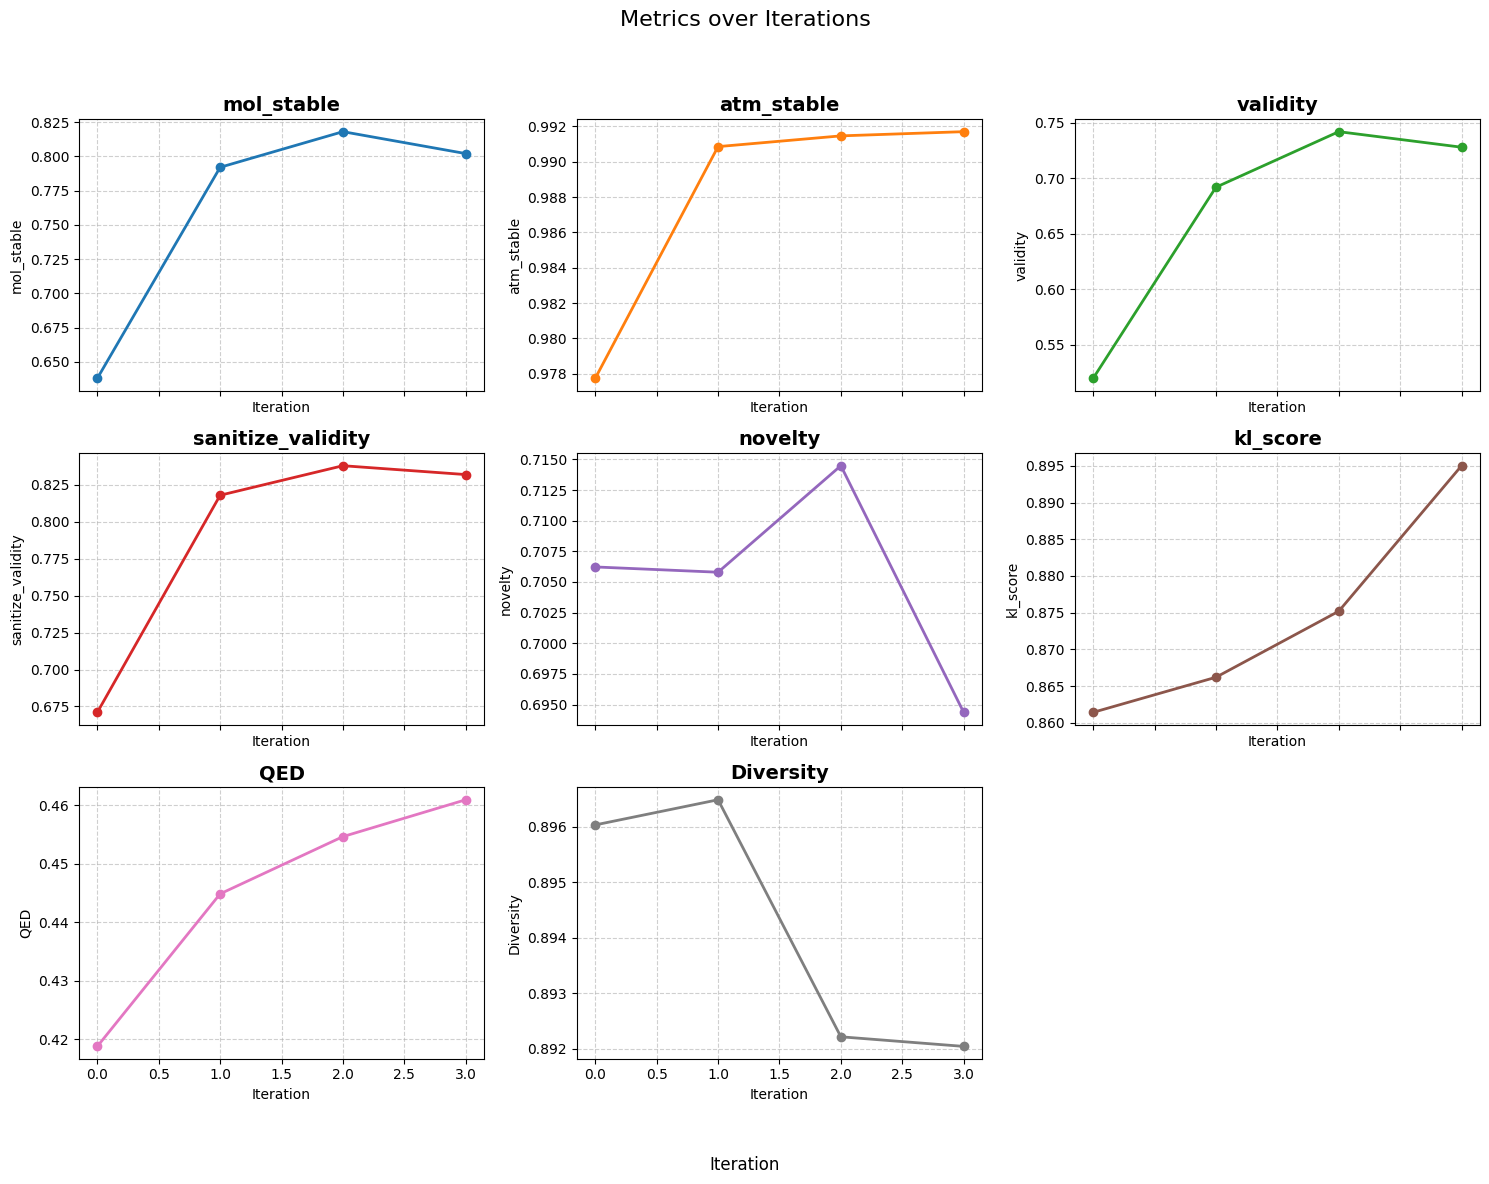

⚠ Missing files:
/data/horse/ws/miha493e-research_project/activediffusion/data/data_40/diffusion_wdir/model_registry/model_iter_4/run0/evaluation.csv


In [7]:
import os
import re

wdirectory = base_dir + "/diffusion_wdir/model_registry"
# Build file_paths automatically and skip missing
file_paths = []
missing_files = []

for folder in sorted(
    [d for d in os.listdir(wdirectory) if re.match(r"model_iter_\d+", d)],
    key=lambda x: int(re.search(r"\d+", x).group())
):
    file_path = os.path.join(wdirectory, folder, "run0", "evaluation.csv")
    if os.path.exists(file_path):
        file_paths.append(file_path)
    else:
        missing_files.append(file_path)

# Now load and plot
df = load_iteration_data_from_paths(file_paths)
metrics = ['mol_stable', 'atm_stable', 'validity', 'sanitize_validity',
           'novelty', 'kl_score', 'QED', 'Diversity']
plot_metrics_subplots(df, metrics)

# Report missing files if any
if missing_files:
    print("⚠ Missing files:")
    for f in missing_files:
        print(f)


### Multi experiments comparison

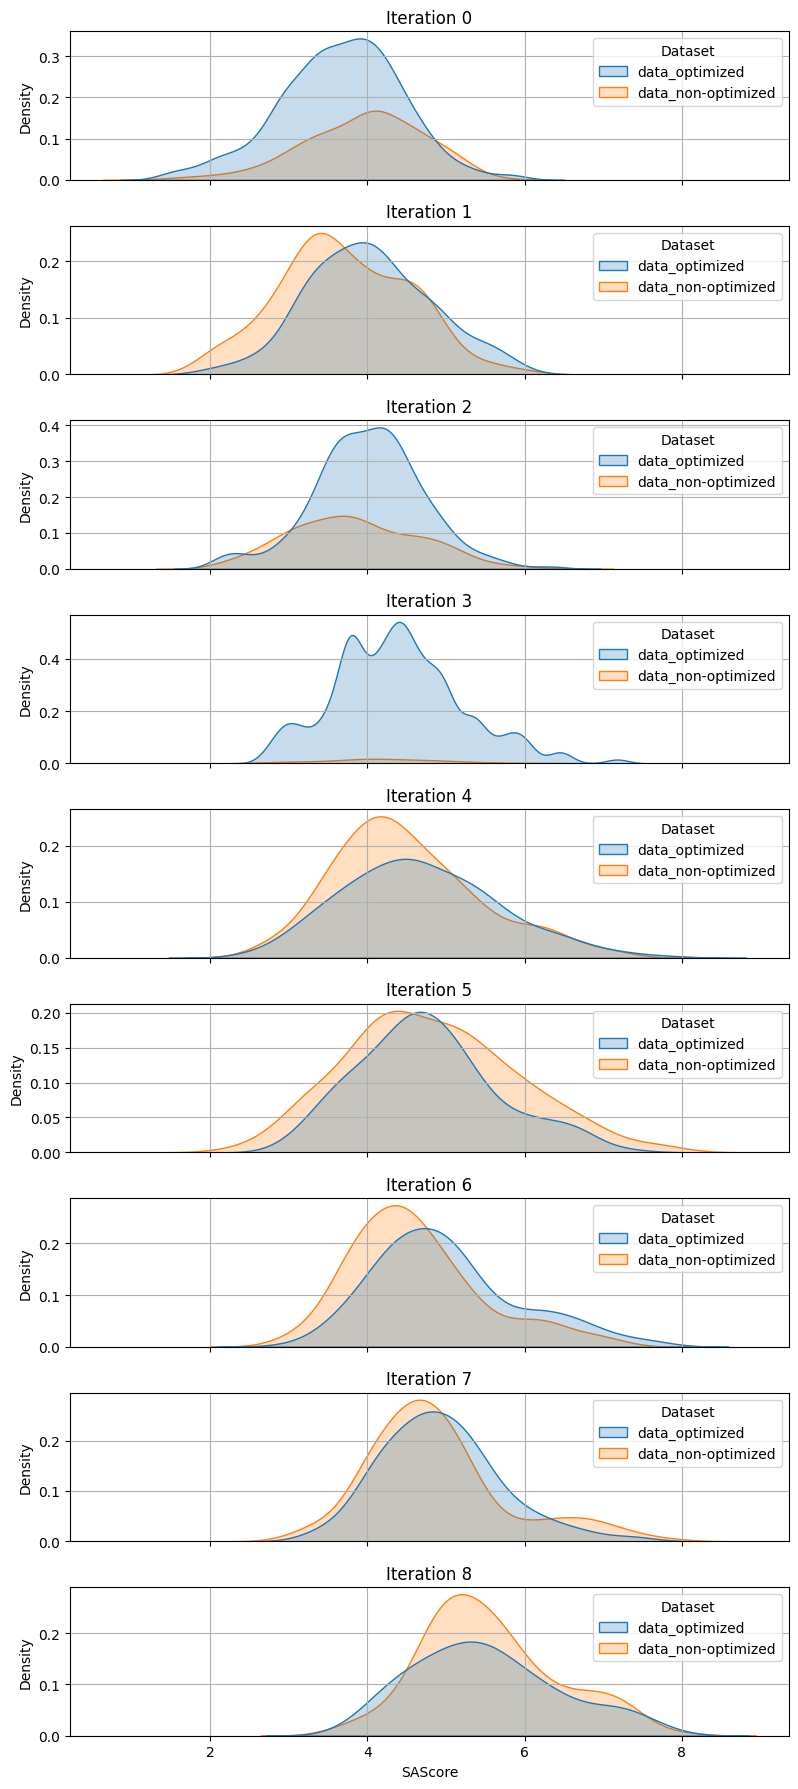

In [3]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import os, re

# ---------- CONFIG ----------
base_dirs = {
    "data_optimized": "/data/horse/ws/miha493e-research_project/activediffusion/data/data_embd_jmp",
    "data_non-optimized": "/data/horse/ws/miha493e-research_project/activediffusion/data/data_embd_non_opt"
}

# ---------- DATA COLLECTION ----------
all_dfs = []

for label, base_dir in base_dirs.items():
    iter_dirs = sorted(
        [d for d in os.listdir(base_dir) if re.match(r"iter_\d+", d)],
        key=lambda x: int(re.search(r"\d+", x).group())
    )
    for iter_dir in iter_dirs:
        sas_file = os.path.join(base_dir, iter_dir, "score_filtered", "sascore.txt")
        if os.path.exists(sas_file):
            try:
                data = pd.read_csv(sas_file, sep=r"\s+", header=None)
                df = pd.DataFrame({
                    "SAScore": data[1],
                    "Iteration": int(re.search(r"\d+", iter_dir).group()),
                    "Dataset": label
                })
                all_dfs.append(df)
            except Exception as e:
                print(f"⚠ Error reading {sas_file}: {e}")

if not all_dfs:
    print("No data found.")
    exit()

df_all = pd.concat(all_dfs, ignore_index=True)

# ---------- PLOTTING ----------
iterations = sorted(df_all["Iteration"].unique())
num_iters = len(iterations)

fig, axes = plt.subplots(num_iters, 1, figsize=(8, 2*num_iters), sharex=True)

if num_iters == 1:
    axes = [axes]  # Ensure axes is iterable

for ax, iter_num in zip(axes, iterations):
    df_iter = df_all[df_all["Iteration"] == iter_num]
    sns.kdeplot(data=df_iter, x="SAScore", hue="Dataset", fill=True, ax=ax)
    ax.set_title(f"Iteration {iter_num}")
    ax.grid(True)

plt.xlabel("SAScore")
plt.tight_layout()
plt.show()

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import os, re
from matplotlib.ticker import MultipleLocator

# ---------- CONFIG ----------
base_dirs = {
    "data_optimized": "/data/horse/ws/miha493e-research_project/activediffusion/data/data_embd_jmp",
    "data_non-optimized": "/data/horse/ws/miha493e-research_project/activediffusion/data/data_embd_non_opt"

}

# ---------- DATA COLLECTION ----------
all_dfs = []

for label, base_dir in base_dirs.items():
    iter_dirs = sorted(
        [d for d in os.listdir(base_dir) if re.match(r"iter_\d+", d)],
        key=lambda x: int(re.search(r"\d+", x).group())
    )
    for iter_dir in iter_dirs:
        sas_file = os.path.join(base_dir, iter_dir, "relaxed", "sascore.txt")
        if os.path.exists(sas_file):
            try:
                data = pd.read_csv(sas_file, sep=r"\s+", header=None)
                df = pd.DataFrame({
                    "SAScore": data[1],
                    "Iteration": int(re.search(r"\d+", iter_dir).group()),
                    "Dataset": label
                })
                all_dfs.append(df)
            except Exception as e:
                print(f"⚠ Error reading {sas_file}: {e}")

if not all_dfs:
    print("No data found.")
    exit()

df_all = pd.concat(all_dfs, ignore_index=True)

# ---------- PLOTTING ----------
datasets = df_all["Dataset"].unique()
iterations = sorted(df_all["Iteration"].unique())
num_iters = len(iterations)

# Prepare fixed colors for each dataset
datasets = df_all["Dataset"].unique()
palette = dict(zip(datasets, sns.color_palette("tab10", len(datasets))))

fig, axes = plt.subplots(num_iters, 1, figsize=(8, 2*num_iters), sharex=True)
if num_iters == 1:
    axes = [axes]

for ax, iter_num in zip(axes, iterations):
    for dataset in datasets:
        df_dataset = df_all[df_all["Dataset"] == dataset]
        
        # Current iteration
        df_curr = df_dataset[df_dataset["Iteration"] == iter_num]
        if not df_curr.empty:
            sns.kdeplot(df_curr["SAScore"], fill=True, ax=ax, alpha=0.3,
                        label=f"{dataset} current", color=palette[dataset])
        
        # Previous iteration
        prev_iter = iter_num - 1
        df_prev = df_dataset[df_dataset["Iteration"] == prev_iter]
        if not df_prev.empty:
            sns.kdeplot(df_prev["SAScore"], fill=False, ax=ax, linestyle='--',
                        label=f"{dataset} prev", color=palette[dataset])

    ax.tick_params(axis='x', labelbottom=True)
    ax.xaxis.set_major_locator(MultipleLocator(1))

    ax.set_title(f"Iteration {iter_num}")
    ax.grid(True)
    ax.legend(fontsize=7, loc='upper right')

plt.xlabel("SAScore")
plt.tight_layout()
plt.show()


No data found.


ValueError: No objects to concatenate

: 

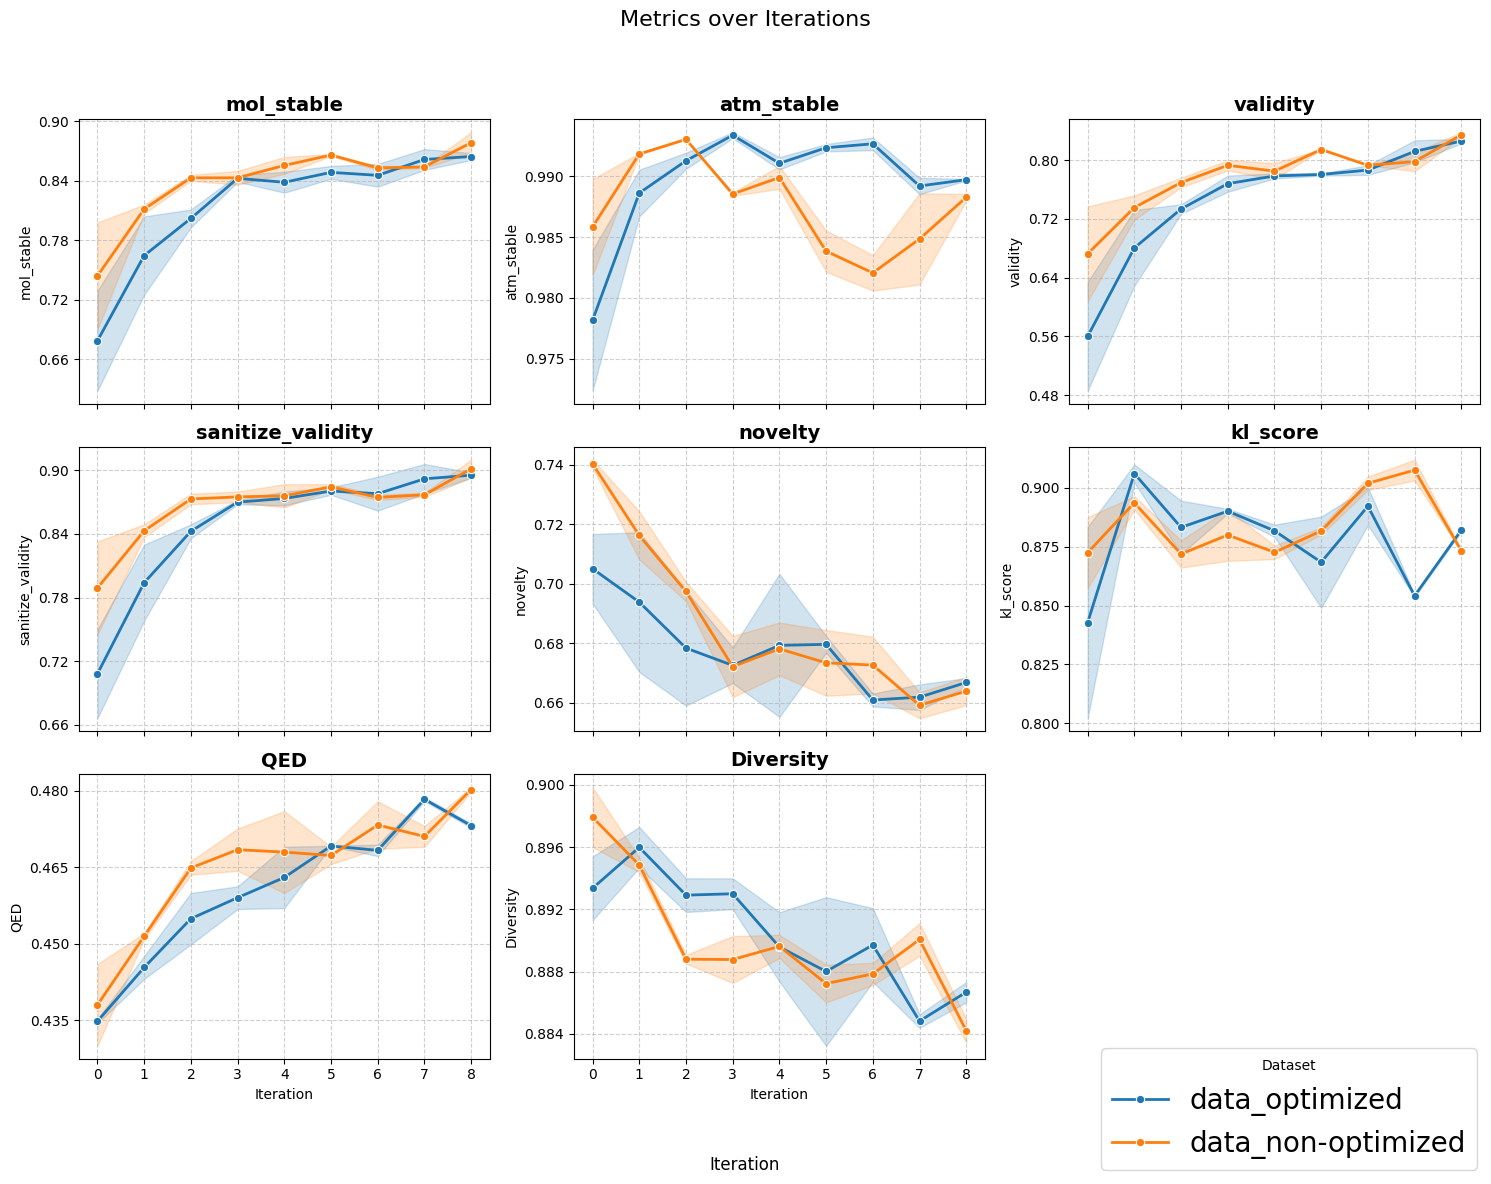

In [1]:
import os
import re
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import math
from matplotlib.ticker import FormatStrFormatter, MaxNLocator

# ---------- CONFIG ----------
base_dirs = {
    "data_optimized": "/data/horse/ws/miha493e-research_project/activediffusion/data/data_embd_jmp",
    "data_non-optimized": "/data/horse/ws/miha493e-research_project/activediffusion/data/data_embd_non_opt"
}

metrics = ['mol_stable', 'atm_stable', 'validity', 'sanitize_validity',
           'novelty', 'kl_score', 'QED', 'Diversity']
# ----------------------------

def collect_iteration_files(base_dir):
    """Collect evaluation.csv files for a given base directory."""
    wdirectory = os.path.join(base_dir, "diffusion_wdir", "model_registry")
    file_paths = []
    missing_files = []

    for folder in sorted(
        [d for d in os.listdir(wdirectory) if re.match(r"model_iter_\d+", d)],
        key=lambda x: int(re.search(r"\d+", x).group())
    ):
        file_path = os.path.join(wdirectory, folder, "run0", "evaluation.csv")
        if os.path.exists(file_path):
            file_paths.append(file_path)
        else:
            missing_files.append(file_path)

    return file_paths, missing_files

def load_iteration_data_from_paths(file_paths, dataset_label):
    """Load CSV files into one DataFrame and add iteration + dataset columns."""
    dfs = []
    for path in file_paths:
        try:
            df = pd.read_csv(path)
            iteration_match = re.search(r"model_iter_(\d+)", path)
            iteration = int(iteration_match.group(1)) if iteration_match else None
            df["iteration"] = iteration
            df["Dataset"] = dataset_label
            dfs.append(df)
        except Exception as e:
            print(f"⚠ Error reading {path}: {e}")
    return pd.concat(dfs, ignore_index=True) if dfs else pd.DataFrame()

def plot_metrics_subplots(df, metrics):
    """Plots each metric in a separate subplot for multiple datasets."""
    if "iteration" not in df.columns:
        print("Column 'iteration' not found in data.")
        return

    # Convert iteration and metrics to numeric
    df["iteration"] = pd.to_numeric(df["iteration"], errors="coerce")
    for metric in metrics:
        if metric in df.columns:
            df[metric] = pd.to_numeric(df[metric], errors="coerce")

    df_sorted = df.sort_values("iteration")
    existing_metrics = [m for m in metrics if m in df.columns]

    if not existing_metrics:
        print("No valid metrics found to plot.")
        return

    num_metrics = len(existing_metrics)
    num_cols = int(math.ceil(math.sqrt(num_metrics)))
    num_rows = int(math.ceil(num_metrics / num_cols))

    fig, axes = plt.subplots(num_rows, num_cols, figsize=(5 * num_cols, 4 * num_rows), sharex=True)
    axes = axes.flatten() if hasattr(axes, "flatten") else [axes]

    palette = sns.color_palette("tab10", len(df["Dataset"].unique()) if "Dataset" in df.columns else len(metrics))
    dataset_order = list(base_dirs.keys())
    for i, metric in enumerate(existing_metrics):
        ax = axes[i]
        if "Dataset" in df.columns:
            sns.lineplot(
                data=df_sorted,
                x="iteration",
                y=metric,
                hue="Dataset",
                hue_order=dataset_order,
                marker="o",
                palette=palette,
                linewidth=2,
                ax=ax,
                sort=False  # Keep order after sorting
            )
            ax.legend_.remove()
        else:
            ax.plot(df_sorted["iteration"], df_sorted[metric], marker='o', color=palette[i], linewidth=2)

        ax.set_title(metric, fontsize=14, fontweight='bold')
        ax.set_xlabel('Iteration', fontsize=10)
        ax.set_ylabel(metric, fontsize=10)
        ax.grid(True, linestyle='--', alpha=0.6)
        ax.yaxis.set_major_locator(MaxNLocator(nbins=5))

    handles, labels = axes[0].get_legend_handles_labels()
    if handles:
        fig.legend(handles, labels, title="Dataset", loc="lower right", fontsize=20)

    fig.supxlabel("Iteration", fontsize=12)
    fig.suptitle("Metrics over Iterations", fontsize=16)

    for j in range(i + 1, len(axes)):
        axes[j].set_visible(False)

    plt.tight_layout(rect=[0, 0.03, 1, 0.95])
    plt.show()

# ---------- MAIN ----------
all_dfs = []
all_missing = []

for label, base_dir in base_dirs.items():
    files, missing = collect_iteration_files(base_dir)
    df = load_iteration_data_from_paths(files, label)
    if not df.empty:
        all_dfs.append(df)
    all_missing.extend(missing)

if all_dfs:
    df_all = pd.concat(all_dfs, ignore_index=True)
    plot_metrics_subplots(df_all, metrics)
else:
    print("No data loaded.")

if all_missing:
    print("⚠ Missing files:")
    for f in all_missing:
        print(f)
